# Lab 2 — Spam classification and Airbnb price outliers

**Course:** CSCN8000  
**Student:** Echezona Oji  
**Student number:** 9078881 

This notebook compares Gaussian and Multinomial Naive Bayes on labelled emails, then compares statistical rules for identifying unusual nightly Airbnb prices. All results below are produced by executable Python cells. The final CSV is free of price outliers **under the selected, fixed rule**, not under every possible definition of an outlier.

## Reproduce this analysis
Unzip the submission and open this notebook in its folder. Install `requirements.txt`, then choose **Restart Kernel and Run All**. The supplied `data/` files allow offline execution. Outputs are written to `results/`. Random seed: 42. The exported `index.html` contains the code, tables, and figures.

In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

SEED = 42
DATA = Path('data')
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 12})
print({'Python': platform.python_version(), 'pandas': pd.__version__,
       'numpy': np.__version__, 'scikit-learn': sklearn.__version__})

{'Python': '3.12.10', 'pandas': '3.0.6', 'numpy': '2.4.6', 'scikit-learn': '1.8.0'}


## Dataset provenance

Both inputs come directly from the [course repository](https://github.com/aaiml/CSCN8000-lab-submissions/blob/main/practical_labs/Lab2.md), at repository commit `d43c8b492a79d3f26d01b273916a11766a9484da`:

- [Lab2_dataset.csv](https://raw.githubusercontent.com/aaiml/CSCN8000-lab-submissions/d43c8b492a79d3f26d01b273916a11766a9484da/practical_labs/Lab2_dataset.csv)
- [AB_NYC_2019.csv](https://raw.githubusercontent.com/aaiml/CSCN8000-lab-submissions/d43c8b492a79d3f26d01b273916a11766a9484da/practical_labs/AB_NYC_2019.csv)

The Airbnb file is a **2019 snapshot**, not current rental-market data. Prices are interpreted as USD per night. Hashes below identify the exact local input files.

In [2]:
for filename in ['Lab2_dataset.csv', 'AB_NYC_2019.csv']:
    print(filename, hashlib.sha256((DATA / filename).read_bytes()).hexdigest())

Lab2_dataset.csv 1fe28948e11da88464f47a33365b894b392a11751b96ab71a3462898accf5ff8
AB_NYC_2019.csv 55426479932e6ac105d3ae86ab1d7de9bb220c29db1a6bdf64d2c4f506329336


## Part A — Email classification

### 1. Inspect and prepare the labels
`ham` means not spam; the positive class is `spam = 1`. Only email text is used as a predictor. `label`, `label_num`, and the exported row index must not become features, because the first two encode the answer and the last is an identifier.

Normalize whitespace and letter case to detect repeated messages. Remove duplicates **before** splitting, so identical normalized emails cannot occur in both training and testing. Check for conflicting labels rather than silently resolving them. Near-duplicates and related email threads may still exist.

In [3]:
emails_raw = pd.read_csv(DATA / 'Lab2_dataset.csv')
assert emails_raw['label'].isin(['ham', 'spam']).all()
assert (emails_raw['label'].map({'ham': 0, 'spam': 1}) == emails_raw['label_num']).all()
print('Original shape:', emails_raw.shape)
display(emails_raw[['label', 'label_num']].value_counts().rename('count').to_frame())
display(emails_raw.isna().sum().rename('missing').to_frame())
emails = emails_raw.dropna(subset=['text', 'label_num']).copy()
emails['text_key'] = emails['text'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
emails = emails.loc[emails['text_key'].ne('')].copy()
conflicts = emails.groupby('text_key')['label_num'].nunique().gt(1).sum()
assert conflicts == 0, 'Resolve conflicting labels before proceeding.'
duplicate_count = emails.duplicated('text_key').sum()
emails = emails.drop_duplicates('text_key').copy()
print(f'Repeated normalized messages removed: {duplicate_count:,}')
print(f'Usable unique messages: {len(emails):,}')

Original shape: (5171, 4)


,,count
label,label_num,
ham,0,3672
spam,1,1499


,missing
Unnamed: 0,0
label,0
text,0
label_num,0


Repeated normalized messages removed: 277
Usable unique messages: 4,894


### 2. Split first, then learn the vocabulary
Use an 80% training / 20% test split, stratified by class to preserve the spam proportion. The test set is held aside until evaluation. `CountVectorizer` learns its vocabulary from training text only, producing nonnegative word counts. Both classifiers receive the same 2,000-feature maximum vocabulary; this bound keeps GaussianNB's dense matrix manageable. These settings are fixed in advance and are not tuned against the test set.

**Comparison criterion:** accuracy is the primary metric for the lab comparison; spam precision, recall, F1, and balanced accuracy expose class-specific weaknesses. A majority-class baseline shows whether the models improve on simply predicting ham.

In [4]:
train_idx, test_idx = train_test_split(emails.index, test_size=0.20,
    random_state=SEED, stratify=emails['label_num'])
train = emails.loc[train_idx].copy()
test = emails.loc[test_idx].copy()
assert set(train['text_key']).isdisjoint(set(test['text_key']))
y_train, y_test = train['label_num'], test['label_num']
display(pd.DataFrame({'train_count': y_train.value_counts(),
                      'test_count': y_test.value_counts(),
                      'train_fraction': y_train.value_counts(normalize=True),
                      'test_fraction': y_test.value_counts(normalize=True)}).rename_axis('label'))
vectorizer = CountVectorizer(lowercase=True, max_features=2000, min_df=2)
X_train = vectorizer.fit_transform(train['text'])
X_test = vectorizer.transform(test['text'])
print('Train and test feature shapes:', X_train.shape, X_test.shape)
print('Dense training matrix size (MiB):', round(X_train.shape[0]*X_train.shape[1]*8/2**20, 1))

,train_count,test_count,train_fraction,test_fraction
label,,,,
0,2745,687,0.701149,0.701736
1,1170,292,0.298851,0.298264


Train and test feature shapes: (3915, 2000) (979, 2000)
Dense training matrix size (MiB): 59.7


### 3. Train Gaussian and Multinomial Naive Bayes

Both models apply Bayes' rule with a simplifying assumption: features are independent conditional on the class. In proportional form,

\[
P(c\mid x) \propto P(c)\prod_j P(x_j\mid c).
\]

GaussianNB models each feature within a class with a normal distribution. Sparse word counts are discrete, often zero, and skewed, so this assumption is questionable here. MultinomialNB models word-count evidence, making it a natural candidate for text. Its `alpha=1` smoothing avoids assigning zero probability to unseen class–word combinations. See the [scikit-learn Naive Bayes guide](https://scikit-learn.org/stable/modules/naive_bayes.html).

GaussianNB requires dense input; MultinomialNB can use the sparse count matrix directly. No scaling that creates negative values is applied.

,accuracy,balanced_accuracy,spam_precision,spam_recall,spam_f1
model,,,,,
GaussianNB,0.9551,0.9571,0.8949,0.9623,0.9274
MultinomialNB,0.9663,0.9681,0.9191,0.9726,0.9451
Majority baseline,0.7017,0.5000,0.0000,0.0000,0.0000


GaussianNB
              precision    recall  f1-score   support

         ham     0.9835    0.9520    0.9675       687
        spam     0.8949    0.9623    0.9274       292

    accuracy                         0.9551       979
   macro avg     0.9392    0.9571    0.9474       979
weighted avg     0.9570    0.9551    0.9555       979

MultinomialNB
              precision    recall  f1-score   support

         ham     0.9881    0.9636    0.9757       687
        spam     0.9191    0.9726    0.9451       292

    accuracy                         0.9663       979
   macro avg     0.9536    0.9681    0.9604       979
weighted avg     0.9675    0.9663    0.9666       979



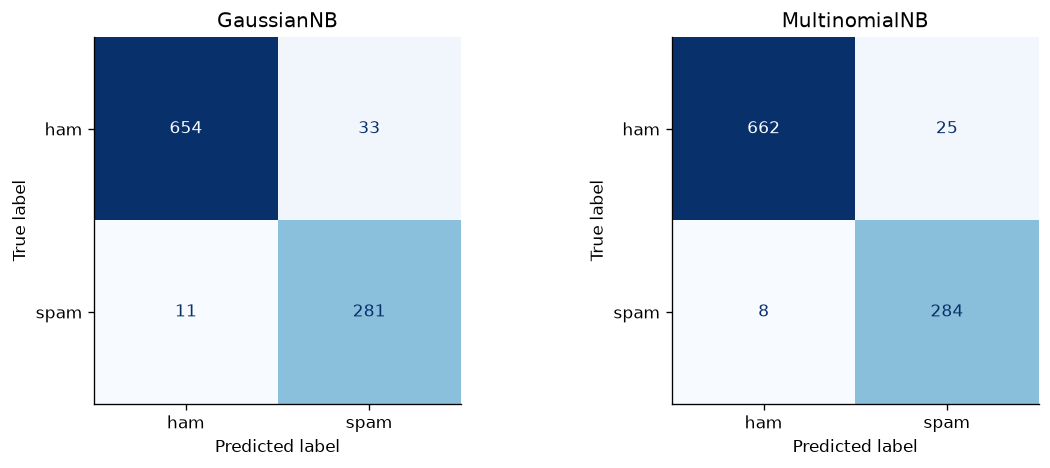

In [5]:
models = {'GaussianNB': GaussianNB(), 'MultinomialNB': MultinomialNB(alpha=1.0)}
predictions = {}
rows = []
for name, model in models.items():
    xtr = X_train.toarray() if name == 'GaussianNB' else X_train
    xte = X_test.toarray() if name == 'GaussianNB' else X_test
    model.fit(xtr, y_train)
    predictions[name] = model.predict(xte)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
predictions['Majority baseline'] = baseline.predict(X_test)
for name, pred in predictions.items():
    rows.append({'model': name, 'accuracy': accuracy_score(y_test, pred),
                 'balanced_accuracy': balanced_accuracy_score(y_test, pred),
                 'spam_precision': precision_score(y_test, pred, zero_division=0),
                 'spam_recall': recall_score(y_test, pred, zero_division=0),
                 'spam_f1': f1_score(y_test, pred, zero_division=0)})
metrics = pd.DataFrame(rows).set_index('model')
display(metrics.round(4))
metrics.to_csv(RESULTS / 'model_metrics.csv')
for name in models:
    print(name)
    print(classification_report(y_test, predictions[name], labels=[0, 1],
                                target_names=['ham', 'spam'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name],
        labels=[0, 1], display_labels=['ham', 'spam'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [6]:
ranked = metrics.loc[list(models)].sort_values(['accuracy', 'spam_f1'], ascending=False)
winner = ranked.index[0]
other = ranked.index[1]
display(Markdown(
    f"**Result:** {winner} performs better on this held-out split: "
    f"accuracy **{metrics.loc[winner, 'accuracy']:.2%}**, versus "
    f"**{metrics.loc[other, 'accuracy']:.2%}** for {other}. "
    f"Its spam F1 is **{metrics.loc[winner, 'spam_f1']:.4f}** and spam recall is "
    f"**{metrics.loc[winner, 'spam_recall']:.2%}**. "
    f"The majority-class baseline accuracy is **{metrics.loc['Majority baseline', 'accuracy']:.2%}**."))

**Result:** MultinomialNB performs better on this held-out split: accuracy **96.63%**, versus **95.51%** for GaussianNB. Its spam F1 is **0.9451** and spam recall is **97.26%**. The majority-class baseline accuracy is **70.17%**.

This is a descriptive comparison on one fixed split, not proof that one classifier always wins. False positives are legitimate emails classified as spam; false negatives are spam allowed through. Different applications may prioritize these errors differently. The test set was used to report which model performed better, so a new independent set would be needed for an unbiased evaluation after further model selection or tuning.

### 4. Predict held-out emails
The following examples are the first 12 test records in the randomized split, not handpicked successes. Both trained classifiers predict the same emails. `P(spam)` is a model estimate, not a calibrated certainty.

In [7]:
examples = pd.DataFrame({'source_row': test.index, 'actual': test['label'].to_numpy(),
    'text_excerpt': test['text'].str.replace(r'\s+', ' ', regex=True).str.slice(0, 110).to_numpy()})
for name, model in models.items():
    xte = X_test.toarray() if name == 'GaussianNB' else X_test
    examples[name] = pd.Series(predictions[name]).map({0: 'ham', 1: 'spam'}).to_numpy()
    spam_col = np.flatnonzero(model.classes_ == 1)[0]
    examples[name + ' P(spam)'] = model.predict_proba(xte)[:, spam_col]
display(examples.head(12).round(4))
examples.to_csv(RESULTS / 'test_predictions.csv', index=False)
errors = examples.loc[examples[winner] != examples['actual']]
print(f'{winner} misclassified {len(errors)} of {len(test)} test emails.')
display(errors.head(5))

,source_row,actual,text_excerpt,GaussianNB,GaussianNB P(spam),MultinomialNB,MultinomialNB P(spam)
0,397,spam,Subject: reply : young natural babies bitch getting their asess fileld with jizz how do you do ?...,spam,1.0,spam,1.0000
1,573,ham,Subject: nom chnage - 7 / 7 / 2000 - eastrans this is to increase our noms for 7 / 7 from hpl in...,ham,0.0,ham,0.0000
2,1689,ham,"Subject: our response to the u . s . tragedy the tragedy of tuesday , september 11 will serve as...",ham,0.0,ham,0.0006
3,4924,spam,"Subject: this site has sweet teen sex , check it o download hot teen movies now ! hot new xxx mo...",spam,1.0,spam,1.0000
4,2312,ham,"Subject: hpl nom for october 26 , 2000 ( see attached file : hplnl 026 . xls ) - hplnl 026 . xls",ham,0.0,ham,0.0000
5,1121,ham,Subject: accum . - - - - - - - - - - - - - - - - - - - - - - forwarded by silver breaux / hou / ...,ham,0.0,ham,0.0000
6,4182,spam,Subject: hlep . . erxs elixir is 5 times more potent than viagra ! - increased circulation and e...,spam,1.0,spam,1.0000
7,1664,ham,"Subject: enron / hpl actuals for january 9 , 2001 teco tap 27 . 500 / enron",ham,0.0,ham,0.0000
8,2203,ham,"Subject: eastrans nomination effective january 1 , 2001 effective 1 / 1 / 01 , the deliveries an...",ham,0.0,ham,0.0000
9,981,ham,"Subject: out of the office i will be out of the office this afternoon , beginning at 1 p . m . s...",ham,0.0,ham,0.0000


MultinomialNB misclassified 33 of 979 test emails.


,source_row,actual,text_excerpt,GaussianNB,GaussianNB P(spam),MultinomialNB,MultinomialNB P(spam)
14,1178,ham,"Subject: my november real estate news update hi there , november is here and it is time to give ...",ham,0.0,spam,1.000000
21,5014,ham,Subject: young families egg hunt bammelyoungfamilies - - - - - - - - - - - - - - - - - - - - - -...,spam,1.0,spam,0.999971
86,546,spam,Subject: re : 1 / 2 price sildenafil citrate today,spam,1.0,ham,0.245985
185,5119,ham,Subject: bpa rate case - seasonal rates - - - - - - - - - - - - - - - - - - - - - - forwarded by...,ham,0.0,spam,1.000000
196,26,ham,Subject: registration confirmation from spinner . com thank you for joining spinner . com : the ...,spam,1.0,spam,1.000000


## Part B — Detect and remove unusual nightly prices

### 1. Inspect the original Airbnb data
A price of zero or a nonfinite/missing price is invalid for this paid-nightly-price analysis and is removed before fitting statistical thresholds. This is a domain rule, distinct from identifying an unusually large valid price. Missing names or review information are retained: this task cleans **price**, not every field. No-review listings should not be discarded simply because review fields are missing.

In [8]:
airbnb_raw = pd.read_csv(DATA / 'AB_NYC_2019.csv')
print('Original shape:', airbnb_raw.shape)
print('Duplicate listing IDs:', airbnb_raw['id'].duplicated().sum())
assert airbnb_raw['id'].is_unique
price_numeric = pd.to_numeric(airbnb_raw['price'], errors='coerce')
valid_mask = price_numeric.notna() & np.isfinite(price_numeric) & price_numeric.gt(0)
airbnb = airbnb_raw.loc[valid_mask].copy()
p = airbnb['price'].astype(float)
print('Invalid prices removed:', (~valid_mask).sum())
display(airbnb_raw.isna().sum().rename('missing').to_frame())
display(p.describe(percentiles=[.01, .25, .50, .75, .95, .99]).rename('USD/night').to_frame())
print(f'Mean: ${p.mean():.2f}; median: ${p.median():.2f}; sample SD: ${p.std():.2f}; skewness: {p.skew():.2f}')

Original shape: (48895, 16)
Duplicate listing IDs: 0
Invalid prices removed: 11


,missing
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


,USD/night
count,48884.000000
mean,152.755053
std,240.170260
min,10.000000
1%,30.000000
25%,69.000000
50%,106.000000
75%,175.000000
95%,355.000000
99%,799.000000


Mean: $152.76; median: $106.00; sample SD: $240.17; skewness: 19.12


### 2. Compare five explicit outlier rules
Each rule is applied **independently to the same positive-price data**, not sequentially.

| Method | Retention rule | Strength and limitation |
|---|---|---|
| Mean / standard deviation | Mean ± 3 sample standard deviations | Simple; extreme high prices inflate both mean and SD, masking other extremes. |
| Median / MAD | Absolute modified z-score ≤ 3.5, where z = 0.67449 × (price − median) / MAD | Robust center and spread; symmetric bounds may overflag a naturally long upper tail. Median alone is not an outlier rule. |
| Percentiles | 1st ≤ price ≤ 99th percentile | Easy to explain; trims tails by policy even if prices are legitimate. Ties affect the exact removal percentage. |
| Global IQR | Q1 − 1.5 IQR ≤ price ≤ Q3 + 1.5 IQR | Robust and transparent; mixes areas and room types with different price levels. |
| Grouped IQR — selected | Same IQR rule within borough × room type | Accounts for local market differences; still a heuristic, and can remove legitimate luxury properties. |

`IQR = Q3 − Q1`; `MAD = median(|price − median|)`. The multipliers are conventional analysis choices, not proof of data errors. The main deliverable uses grouped IQR because comparing a shared room with an entire Manhattan home using one universal upper bound is less informative. This policy is selected for its interpretation, not because it removes a desired number of rows.

In [9]:
mean, sd = p.mean(), p.std(ddof=1)
median = p.median()
mad = (p - median).abs().median()
assert mad > 0
q1, q3 = p.quantile([.25, .75])
iqr = q3 - q1
bounds = {
    'Mean ± 3 SD': (mean - 3*sd, mean + 3*sd),
    'Median / MAD': (median - 3.5*mad/0.67449, median + 3.5*mad/0.67449),
    '1–99 percentiles': tuple(p.quantile([.01, .99])),
    'Global IQR': (q1 - 1.5*iqr, q3 + 1.5*iqr)
}
keep = {name: p.between(lo, hi, inclusive='both') for name, (lo, hi) in bounds.items()}
display(pd.DataFrame(bounds, index=['lower_USD', 'upper_USD']).T.round(2))

group_cols = ['neighbourhood_group', 'room_type']
assert airbnb[group_cols].notna().all().all()
grouped = airbnb.groupby(group_cols)['price']
fences = grouped.agg(n='size', median='median', mean='mean')
fences['q1'] = grouped.quantile(.25)
fences['q3'] = grouped.quantile(.75)
fences['iqr'] = fences['q3'] - fences['q1']
# Fallback protects a future dataset containing tiny or constant-price groups.
fences['use_global_fallback'] = (fences['n'] < 30) | (fences['iqr'] == 0)
fences['lower'] = (fences['q1'] - 1.5*fences['iqr']).where(~fences['use_global_fallback'], bounds['Global IQR'][0])
fences['upper'] = (fences['q3'] + 1.5*fences['iqr']).where(~fences['use_global_fallback'], bounds['Global IQR'][1])
row_bounds = airbnb[group_cols].join(fences[['lower', 'upper']], on=group_cols)
keep['Grouped IQR'] = p.between(row_bounds['lower'], row_bounds['upper'], inclusive='both')
display(fences.round(2))
fences.to_csv(RESULTS / 'group_price_thresholds.csv')
comparison = []
for method, mask in keep.items():
    retained = p.loc[mask]
    comparison.append({'method': method, 'kept': int(mask.sum()), 'removed': int((~mask).sum()),
        'removed_pct': 100*(~mask).mean(), 'mean': retained.mean(), 'median': retained.median(),
        'std': retained.std(), 'min': retained.min(), 'max': retained.max()})
comparison = pd.DataFrame(comparison).set_index('method')
display(comparison.round(2))
comparison.to_csv(RESULTS / 'outlier_method_comparison.csv')

,lower_USD,upper_USD
Mean ± 3 SD,-567.76,873.27
Median / MAD,-132.70,344.70
1–99 percentiles,30.00,799.00
Global IQR,-90.00,334.00


n  median    mean     q1      q3  \
neighbourhood_group room_type                                               
Bronx               Entire home/apt    379   100.0  127.51   80.0  140.00   
                    Private room       651    54.0   66.89   40.0   70.00   
                    Shared room         60    40.0   59.80   28.0   55.50   
Brooklyn            Entire home/apt   9558   145.0  178.35  105.0  199.00   
                    Private room     10126    65.0   76.55   50.0   80.00   
                    Shared room        411    36.0   50.77   30.0   50.00   
Manhattan           Entire home/apt  13198   191.0  249.26  143.0  259.00   
                    Private room      7982    90.0  116.78   68.0  120.00   
                    Shared room        480    69.0   88.98   49.0   89.25   
Queens              Entire home/apt   2096   120.0  147.05   90.0  168.25   
                    Private room      3372    60.0   71.76   47.0   75.00   
                    Shared room        198    37.0   69.02   30.0   54.25   
Staten Island       Entire home/apt    176   100.0  173.85   75.0  151.25   
                    Private room       188    50.0   62.29   40.0   75.00   
                    Shared room          9    30.0   57.44   29.0   75.00   

                                        iqr  use_global_fallback  lower  \
neighbourhood_group room_type                                             
Bronx               Entire home/apt   60.00                False -10.00   
                    Private room      30.00                False  -5.00   
                    Shared room       27.50                False -13.25   
Brooklyn            Entire home/apt   94.00                False -36.00   
                    Private room      30.00                False   5.00   
                    Shared room       20.00                False   0.00   
Manhattan           Entire home/apt  116.00                False -31.00   
                    Private room      52.00                False -10.00   
                    Shared room       40.25                False -11.38   
Queens              Entire home/apt   78.25                False -27.38   
                    Private room      28.00                False   5.00   
                    Shared room       24.25                False  -6.38   
Staten Island       Entire home/apt   76.25                False -39.38   
                    Private room      35.00                False -12.50   
                    Shared room       46.00                 True -90.00   

                                      upper  
neighbourhood_group room_type                
Bronx               Entire home/apt  230.00  
                    Private room     115.00  
                    Shared room       96.75  
Brooklyn            Entire home/apt  340.00  
                    Private room     125.00  
                    Shared room       80.00  
Manhattan           Entire home/apt  433.00  
                    Private room     198.00  
                    Shared room      149.62  
Queens              Entire home/apt  285.62  
                    Private room     117.00  
                    Shared room       90.62  
Staten Island       Entire home/apt  265.62  
                    Private room     127.50  
                    Shared room      334.00

,kept,removed,removed_pct,mean,median,std,min,max
method,,,,,,,,
Mean ± 3 SD,48496,388,0.79,138.78,105.0,107.55,10.0,860.0
Median / MAD,45968,2916,5.97,120.27,100.0,68.52,10.0,344.0
1–99 percentiles,48017,867,1.77,138.50,105.0,103.69,30.0,799.0
Global IQR,45912,2972,6.08,120.00,100.0,68.13,10.0,334.0
Grouped IQR,45408,3476,7.11,122.56,100.0,75.26,10.0,433.0


### 3. Visualize the effect and inspect group differences
The first plot uses a logarithmic horizontal axis to show the entire positive-price range without hiding the upper tail. The second uses the same scale before and after cleaning. The final plot compares retained mean and median prices for every rule.

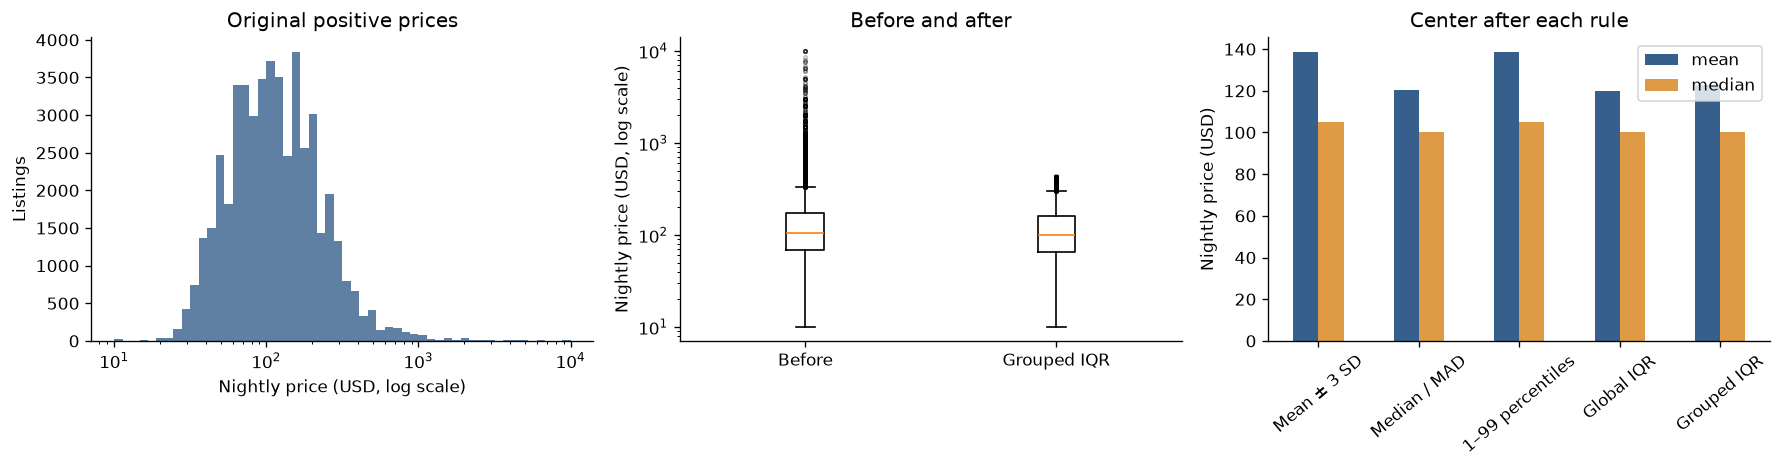

original  removed  removed_pct
neighbourhood_group room_type                                      
Bronx               Entire home/apt       379       33         8.71
                    Private room          651       39         5.99
                    Shared room            60        5         8.33
Brooklyn            Entire home/apt      9558      612         6.40
                    Private room        10126      598         5.91
                    Shared room           411       45        10.95
Manhattan           Entire home/apt     13198     1051         7.96
                    Private room         7982      658         8.24
                    Shared room           480       48        10.00
Queens              Entire home/apt      2096      122         5.82
                    Private room         3372      220         6.52
                    Shared room           198       21        10.61
Staten Island       Entire home/apt       176       17         9.66
                    Private room          188        7         3.72
                    Shared room             9        0         0.00

In [10]:
clean = airbnb.loc[keep['Grouped IQR']].copy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bins = np.geomspace(p.min(), p.max(), 55)
axes[0].hist(p, bins=bins, color='#375f8c', alpha=.8)
axes[0].set_xscale('log')
axes[0].set(title='Original positive prices', xlabel='Nightly price (USD, log scale)', ylabel='Listings')
axes[1].boxplot([p, clean['price']], tick_labels=['Before', 'Grouped IQR'], showfliers=True,
                flierprops={'markersize': 2, 'alpha': .25})
axes[1].set_yscale('log')
axes[1].set(title='Before and after', ylabel='Nightly price (USD, log scale)')
comparison[['mean', 'median']].plot.bar(ax=axes[2], color=['#375f8c', '#df9a46'])
axes[2].set(title='Center after each rule', ylabel='Nightly price (USD)', xlabel='')
axes[2].tick_params(axis='x', rotation=40)
plt.tight_layout()
plt.show()

group_effect = airbnb.assign(removed=~keep['Grouped IQR']).groupby(group_cols).agg(
    original=('id', 'size'), removed=('removed', 'sum'))
group_effect['removed_pct'] = 100*group_effect['removed']/group_effect['original']
display(group_effect.round(2))
group_effect.to_csv(RESULTS / 'group_removal_summary.csv')

### Interpretation and limitations
The large difference between the original mean and median, together with the long upper tail, explains why the mean is less representative of a typical listing. SD is also sensitive to extreme values, so mean ± 3 SD can leave substantial high-price observations. Median/MAD and IQR reduce that influence. Percentiles make the trimming policy explicit, but do not distinguish errors from rare legitimate listings.

Grouped IQR provides a reproducible, context-aware definition for this lab. It does not establish that excluded listings are incorrect: luxury rentals, unusual properties, and data-entry errors cannot be distinguished from price alone. Borough and room type are only coarse controls; neighbourhood, capacity, season, and amenities may explain more variation. Removal rates by group should be reviewed before using the cleaned file for market comparisons. Missing non-price fields remain, and this snapshot cannot support claims about current New York prices.